# Heart Failure Mortality Prediction
## Comparative Evaluation of Statistical, Machine Learning, and Hybrid Approaches

**Research Aim:** To investigate whether integrating statistical and machine learning models
through a hybrid stacking approach improves predictive performance, interpretability, and
generalizability compared with individual models, for heart failure mortality prediction.

**Dataset:** Heart Failure Clinical Records Dataset (299 patients, 13 variables).
Place `heart_failure_clinical_records_dataset.csv` in the same folder as this notebook,
or edit `DATA_PATH` in the cell below.

**Structure:**
1. Setup & Imports
2. Phase 1 — Exploratory Data Analysis
3. Phase 2 — Data Preparation (Feature Set A, train/test split, CV scheme)
4. Phase 2b — Class Imbalance Strategy Comparison
5. Phase 3 — Logistic Regression (statistical baseline)
6. Phase 3b — Linear Discriminant Analysis (second statistical model)
7. Phase 4 — Decision Tree
8. Phase 5 — Random Forest
9. Phase 6 — XGBoost
10. Phase 7 — Model Comparison & Selection
11. Phase 8 — Sensitivity Analysis (`time` variable / data leakage)
12. Phase 9 — Hybrid Stacking Model
13. Phase 9b — SHAP Explainability
14. Phase 10 — Final Comparison with Bootstrap 95% Confidence Intervals


## 1. Setup & Imports

In [1]:

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
                              average_precision_score, brier_score_loss, confusion_matrix,
                              accuracy_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import shap

DATA_PATH = 'heart_failure_clinical_records_dataset.csv'
RANDOM_STATE = 42


## 2. Phase 1 — Exploratory Data Analysis

Descriptive statistics, class balance, missingness, outlier assessment, and correlation
analysis. See the accompanying EDA Report for full narrative discussion.

In [2]:

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df.dtypes)
df.head()


Shape: (299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:

# Class balance
print(df['DEATH_EVENT'].value_counts())
print(df['DEATH_EVENT'].value_counts(normalize=True))

# Missing values
print("\nMissing cells:", df.isnull().sum().sum())

# Outlier check (IQR method)
print("\nOutliers (IQR method):")
for col in ['creatinine_phosphokinase','serum_creatinine','platelets','ejection_fraction']:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"  {col}: {n_out} outliers ({n_out/len(df):.1%})")


DEATH_EVENT
0    203
1     96
Name: count, dtype: int64
DEATH_EVENT
0    0.67893
1    0.32107
Name: proportion, dtype: float64

Missing cells: 0

Outliers (IQR method):
  creatinine_phosphokinase: 29 outliers (9.7%)
  serum_creatinine: 29 outliers (9.7%)
  platelets: 21 outliers (7.0%)
  ejection_fraction: 2 outliers (0.7%)


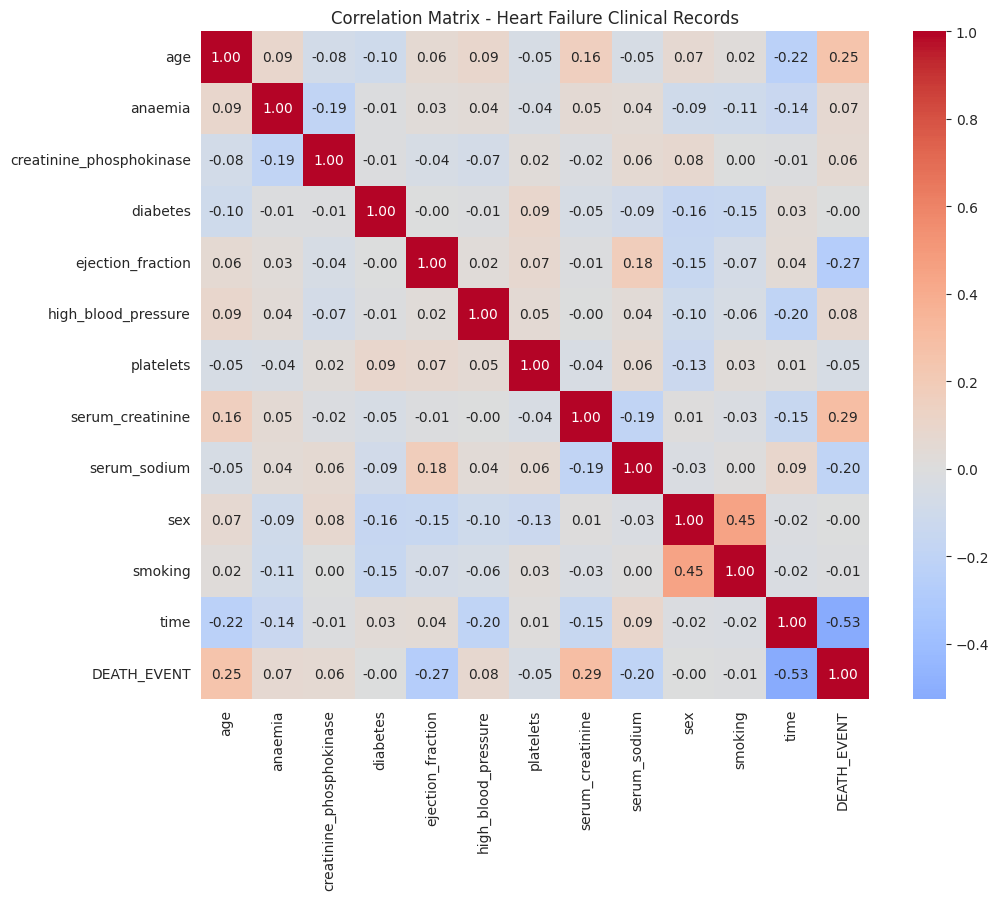


Correlation with target, sorted:
DEATH_EVENT                 1.000000
serum_creatinine            0.294278
age                         0.253729
high_blood_pressure         0.079351
anaemia                     0.066270
creatinine_phosphokinase    0.062728
diabetes                   -0.001943
sex                        -0.004316
smoking                    -0.012623
platelets                  -0.049139
serum_sodium               -0.195204
ejection_fraction          -0.268603
time                       -0.526964
Name: DEATH_EVENT, dtype: float64


In [4]:

# Correlation heatmap
plt.figure(figsize=(11, 9))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Matrix - Heart Failure Clinical Records')
plt.tight_layout()
plt.show()

print("\nCorrelation with target, sorted:")
print(corr['DEATH_EVENT'].sort_values(ascending=False))


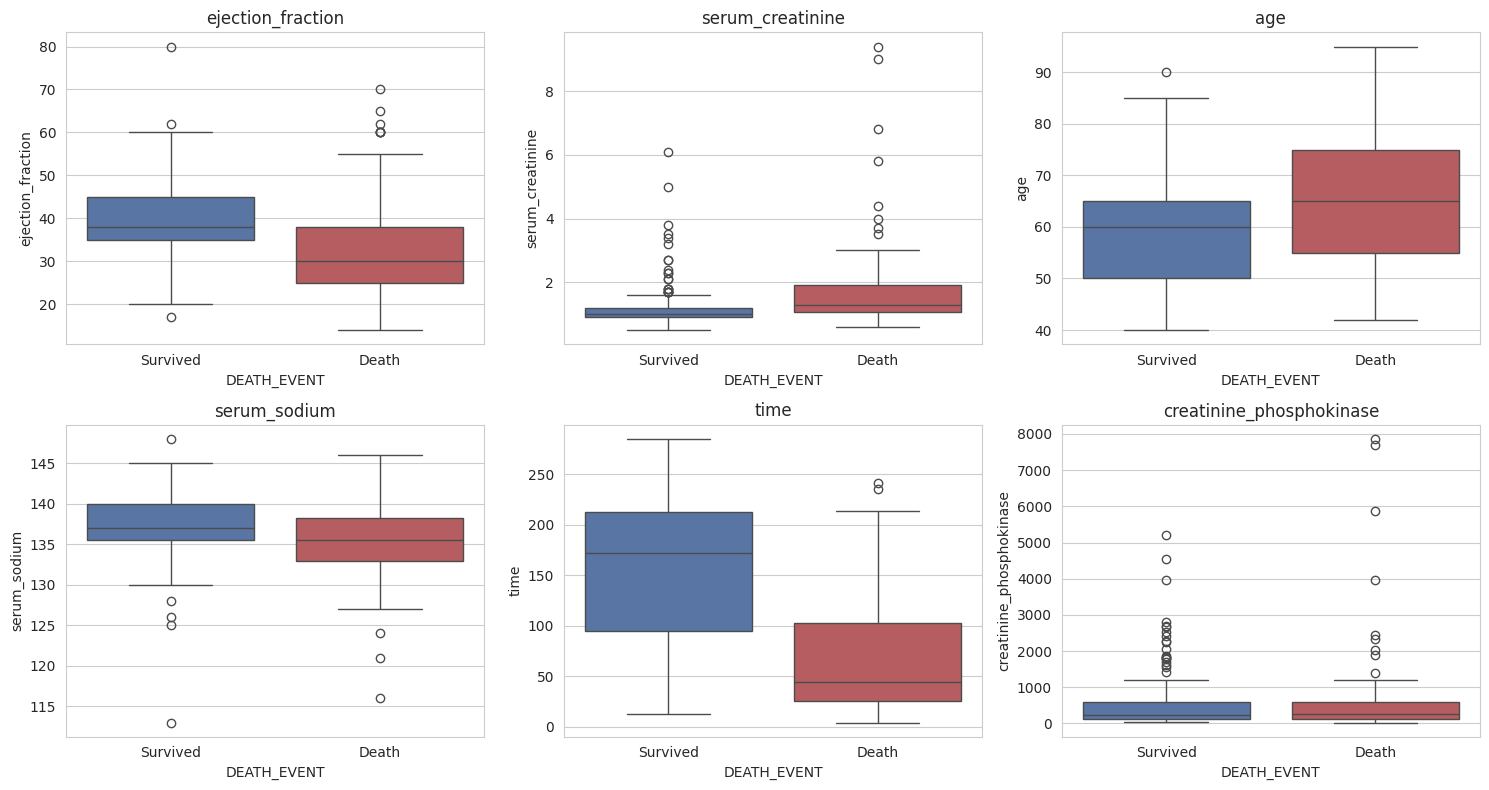

In [5]:

# Outcome-stratified distributions of key clinical variables
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
feats = ['ejection_fraction','serum_creatinine','age','serum_sodium','time','creatinine_phosphokinase']
for ax, f in zip(axes.flat, feats):
    sns.boxplot(x='DEATH_EVENT', y=f, data=df, ax=ax, palette=['#4C72B0', '#C44E52'])
    ax.set_xticklabels(['Survived', 'Death'])
    ax.set_title(f)
plt.tight_layout()
plt.show()


## 3. Phase 2 — Data Preparation

**Feature Set A (primary):** all 11 admission variables, `time` excluded to avoid data leakage
(it represents follow-up duration, unknown at the point a real prediction is needed).
`time` is retained separately only for the Phase 8 sensitivity analysis.

**Split:** 80% train / 20% test, stratified, held out until final evaluation.

**CV scheme:** plain stratified 5-fold, shared identically across every model for fair comparison.

In [6]:

TARGET = 'DEATH_EVENT'
feature_set_A = [c for c in df.columns if c not in [TARGET, 'time']]
feature_set_A_plus = feature_set_A + ['time']   # sensitivity analysis only

X_A = df[feature_set_A].copy()
X_Aplus = df[feature_set_A_plus].copy()
y = df[TARGET].copy()

X_train_A, X_test_A, y_train, y_test = train_test_split(
    X_A, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
# same patients, time-included version, for Phase 8
X_train_Aplus = X_Aplus.loc[X_train_A.index]
X_test_Aplus  = X_Aplus.loc[X_test_A.index]

print(f"Train: {X_train_A.shape[0]} patients ({y_train.mean():.1%} death rate)")
print(f"Test:  {X_test_A.shape[0]} patients ({y_test.mean():.1%} death rate)")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Train: 239 patients (32.2% death rate)
Test:  60 patients (31.7% death rate)


## 4. Phase 2b — Class Imbalance Strategy Comparison

Compares no correction, `class_weight='balanced'`, and SMOTE (applied fold-safe via an
imblearn Pipeline, never before the train/test split) using Logistic Regression as a neutral
test model. The winning strategy (class weighting) is used as the default for every model
in this notebook.

In [7]:

scoring = ['roc_auc', 'f1', 'average_precision']
from sklearn.model_selection import cross_validate

imbalance_results = {}
imbalance_results['none'] = cross_validate(
    ImbPipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    X_train_A, y_train, cv=cv, scoring=scoring, n_jobs=-1)

imbalance_results['class_weight'] = cross_validate(
    ImbPipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))]),
    X_train_A, y_train, cv=cv, scoring=scoring, n_jobs=-1)

imbalance_results['smote'] = cross_validate(
    ImbPipeline([('scale', StandardScaler()), ('smote', SMOTE(random_state=RANDOM_STATE)), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    X_train_A, y_train, cv=cv, scoring=scoring, n_jobs=-1)

print(f"{'Strategy':<15}{'ROC-AUC':<20}{'F1':<20}{'PR-AUC':<20}")
for name, r in imbalance_results.items():
    auc, f1, pr = r['test_roc_auc'], r['test_f1'], r['test_average_precision']
    print(f"{name:<15}{auc.mean():.3f} +/- {auc.std():.3f}    {f1.mean():.3f} +/- {f1.std():.3f}    {pr.mean():.3f} +/- {pr.std():.3f}")

# Decision: class_weight='balanced' used throughout (best F1, lowest variance)


Strategy       ROC-AUC             F1                  PR-AUC              
none           0.805 +/- 0.052    0.520 +/- 0.054    0.685 +/- 0.041
class_weight   0.804 +/- 0.050    0.669 +/- 0.028    0.686 +/- 0.052
smote          0.790 +/- 0.047    0.668 +/- 0.021    0.668 +/- 0.045


## 5. Phase 3 — Logistic Regression (Statistical Baseline)

Tuned via GridSearchCV over L1/L2/Elastic-Net penalties, using `class_weight='balanced'`.

In [8]:

def evaluate_model(model, X_test, y_test):
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return {
        'accuracy': accuracy_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_prob),
        'pr_auc': average_precision_score(y_test, y_prob),
        'f1': f1_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall_sensitivity': recall_score(y_test, y_pred),
        'specificity': tn / (tn + fp),
        'brier_score': brier_score_loss(y_test, y_prob),
    }, y_prob, y_pred

results = {}   # collects {model_name: {'metrics':..., 'y_prob':..., 'y_pred':...}}


In [9]:

pipe_lr = Pipeline([('scale', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))])

param_grid_lr = [
    {'clf__penalty': ['l2'], 'clf__C': [0.01,0.03,0.1,0.3,1,3,10], 'clf__solver': ['lbfgs']},
    {'clf__penalty': ['l1'], 'clf__C': [0.01,0.03,0.1,0.3,1,3,10], 'clf__solver': ['liblinear']},
    {'clf__penalty': ['elasticnet'], 'clf__C': [0.1,1,10], 'clf__l1_ratio': [0.3,0.5,0.7], 'clf__solver': ['saga']},
]
grid_lr = GridSearchCV(pipe_lr, param_grid_lr, scoring='roc_auc', cv=cv, n_jobs=-1, refit=True)
grid_lr.fit(X_train_A, y_train)
print("Best params:", grid_lr.best_params_, "| CV ROC-AUC:", round(grid_lr.best_score_, 4))

lr_model = grid_lr.best_estimator_
m, yp, yhat = evaluate_model(lr_model, X_test_A, y_test)
results['Logistic Regression'] = {'metrics': m, 'y_prob': yp, 'y_pred': yhat, 'model': lr_model, 'best_params': grid_lr.best_params_}
print(m)


Best params: {'clf__C': 10, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'} | CV ROC-AUC: 0.8044
{'accuracy': 0.6833333333333333, 'roc_auc': 0.7342747111681642, 'pr_auc': 0.5913748957259026, 'f1': 0.5128205128205128, 'precision': 0.5, 'recall_sensitivity': 0.5263157894736842, 'specificity': np.float64(0.7560975609756098), 'brier_score': 0.20268484199959388}


In [10]:

# Interpretability: odds ratios
coefs = lr_model.named_steps['clf'].coef_[0]
odds_ratios = np.exp(coefs)
coef_df = pd.DataFrame({'feature': feature_set_A, 'coefficient': coefs, 'odds_ratio': odds_ratios}) \
            .sort_values('odds_ratio', ascending=False)
print(coef_df.to_string(index=False))


                 feature  coefficient  odds_ratio
        serum_creatinine     1.079493    2.943187
                     age     0.478537    1.613712
                 anaemia     0.349052    1.417722
creatinine_phosphokinase     0.346843    1.414595
     high_blood_pressure     0.324240    1.382979
                diabetes     0.288409    1.334303
                 smoking     0.222818    1.249593
                     sex    -0.114758    0.891582
               platelets    -0.133995    0.874594
            serum_sodium    -0.182439    0.833235
       ejection_fraction    -0.783834    0.456652


## 6. Phase 3b — Linear Discriminant Analysis (Second Statistical Model)

Included to broaden the statistical comparison (LR is treated as the primary, benchmark
statistical model; LDA as a second classical statistical classifier with different
distributional assumptions). LDA has no native class-weighting; imbalance is instead handled
via balanced priors (0.5/0.5) as a tunable option.

In [11]:

pipe_lda = Pipeline([('scale', StandardScaler()), ('clf', LinearDiscriminantAnalysis())])

param_grid_lda = [
    {'clf__solver': ['svd'], 'clf__priors': [None, [0.5, 0.5]]},
    {'clf__solver': ['lsqr'], 'clf__shrinkage': [None, 'auto', 0.1, 0.3, 0.5, 0.7, 0.9], 'clf__priors': [None, [0.5, 0.5]]},
]
grid_lda = GridSearchCV(pipe_lda, param_grid_lda, scoring='roc_auc', cv=cv, n_jobs=-1, refit=True)
grid_lda.fit(X_train_A, y_train)
print("Best params:", grid_lda.best_params_, "| CV ROC-AUC:", round(grid_lda.best_score_, 4))

lda_model = grid_lda.best_estimator_
m, yp, yhat = evaluate_model(lda_model, X_test_A, y_test)
results['LDA'] = {'metrics': m, 'y_prob': yp, 'y_pred': yhat, 'model': lda_model, 'best_params': grid_lda.best_params_}
print(m)


Best params: {'clf__priors': None, 'clf__solver': 'svd'} | CV ROC-AUC: 0.8013
{'accuracy': 0.7166666666666667, 'roc_auc': 0.7471116816431321, 'pr_auc': 0.6095167571474946, 'f1': 0.45161290322580644, 'precision': 0.5833333333333334, 'recall_sensitivity': 0.3684210526315789, 'specificity': np.float64(0.8780487804878049), 'brier_score': 0.18389555008385008}


## 7. Phase 4 — Decision Tree (First Machine Learning Model)

In [12]:

pipe_dt = Pipeline([('clf', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE))])
param_grid_dt = {
    'clf__max_depth': [2,3,4,5,6,8,10,None],
    'clf__min_samples_split': [2,5,10,20],
    'clf__min_samples_leaf': [1,5,10,15],
    'clf__ccp_alpha': [0.0,0.001,0.005,0.01,0.02],
}
grid_dt = GridSearchCV(pipe_dt, param_grid_dt, scoring='roc_auc', cv=cv, n_jobs=-1, refit=True)
grid_dt.fit(X_train_A, y_train)
print("Best params:", grid_dt.best_params_, "| CV ROC-AUC:", round(grid_dt.best_score_, 4))

dt_model = grid_dt.best_estimator_
m, yp, yhat = evaluate_model(dt_model, X_test_A, y_test)
results['Decision Tree'] = {'metrics': m, 'y_prob': yp, 'y_pred': yhat, 'model': dt_model, 'best_params': grid_dt.best_params_}
print(m)

imp_df = pd.DataFrame({'feature': feature_set_A, 'importance': dt_model.named_steps['clf'].feature_importances_}) \
           .sort_values('importance', ascending=False)
print(imp_df.to_string(index=False))


Best params: {'clf__ccp_alpha': 0.0, 'clf__max_depth': 4, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 2} | CV ROC-AUC: 0.7272
{'accuracy': 0.7333333333333333, 'roc_auc': 0.7644415917843388, 'pr_auc': 0.5308175742386269, 'f1': 0.6363636363636364, 'precision': 0.56, 'recall_sensitivity': 0.7368421052631579, 'specificity': np.float64(0.7317073170731707), 'brier_score': 0.195652963931469}
                 feature  importance
        serum_creatinine    0.340191
       ejection_fraction    0.285765
                     age    0.147257
creatinine_phosphokinase    0.094071
            serum_sodium    0.069316
                     sex    0.040480
                 smoking    0.022921
                 anaemia    0.000000
               platelets    0.000000
                diabetes    0.000000
     high_blood_pressure    0.000000


## 8. Phase 5 — Random Forest

Uses RandomizedSearchCV (40 sampled configurations) rather than exhaustive GridSearchCV,
since the full grid is too large to search exhaustively in reasonable time.

In [13]:

pipe_rf = Pipeline([('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))])
param_grid_rf = {
    'clf__n_estimators': [100,200,300],
    'clf__max_depth': [3,4,5,6,None],
    'clf__max_features': ['sqrt','log2',0.5],
    'clf__min_samples_leaf': [1,3,5,10],
}
grid_rf = RandomizedSearchCV(pipe_rf, param_grid_rf, n_iter=40, scoring='roc_auc', cv=cv,
                              n_jobs=-1, refit=True, random_state=RANDOM_STATE)
grid_rf.fit(X_train_A, y_train)
print("Best params:", grid_rf.best_params_, "| CV ROC-AUC:", round(grid_rf.best_score_, 4))

rf_model = grid_rf.best_estimator_
m, yp, yhat = evaluate_model(rf_model, X_test_A, y_test)
results['Random Forest'] = {'metrics': m, 'y_prob': yp, 'y_pred': yhat, 'model': rf_model, 'best_params': grid_rf.best_params_}
print(m)

imp_df = pd.DataFrame({'feature': feature_set_A, 'importance': rf_model.named_steps['clf'].feature_importances_}) \
           .sort_values('importance', ascending=False)
print(imp_df.to_string(index=False))


Best params: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 5, 'clf__max_features': 0.5, 'clf__max_depth': 3} | CV ROC-AUC: 0.7965
{'accuracy': 0.7333333333333333, 'roc_auc': 0.785622593068036, 'pr_auc': 0.5877450591884803, 'f1': 0.5789473684210527, 'precision': 0.5789473684210527, 'recall_sensitivity': 0.5789473684210527, 'specificity': np.float64(0.8048780487804879), 'brier_score': 0.1854694526786225}
                 feature  importance
        serum_creatinine    0.389066
       ejection_fraction    0.296706
                     age    0.094751
            serum_sodium    0.077177
               platelets    0.050928
creatinine_phosphokinase    0.050701
     high_blood_pressure    0.012082
                 smoking    0.010252
                 anaemia    0.008454
                diabetes    0.006328
                     sex    0.003554


## 9. Phase 6 — XGBoost

Uses `scale_pos_weight` (XGBoost's native equivalent of `class_weight='balanced'`) and
RandomizedSearchCV for the same reason as Random Forest.

In [14]:

n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = n_neg / n_pos

pipe_xgb = Pipeline([('clf', XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                                             random_state=RANDOM_STATE, n_jobs=-1))])
param_grid_xgb = {
    'clf__n_estimators': [50,100,200,300],
    'clf__max_depth': [2,3,4,5],
    'clf__learning_rate': [0.01,0.03,0.05,0.1,0.2],
    'clf__subsample': [0.6,0.8,1.0],
    'clf__colsample_bytree': [0.6,0.8,1.0],
    'clf__min_child_weight': [1,3,5],
}
grid_xgb = RandomizedSearchCV(pipe_xgb, param_grid_xgb, n_iter=50, scoring='roc_auc', cv=cv,
                               n_jobs=-1, refit=True, random_state=RANDOM_STATE)
grid_xgb.fit(X_train_A, y_train)
print("Best params:", grid_xgb.best_params_, "| CV ROC-AUC:", round(grid_xgb.best_score_, 4))

xgb_model = grid_xgb.best_estimator_
m, yp, yhat = evaluate_model(xgb_model, X_test_A, y_test)
results['XGBoost'] = {'metrics': m, 'y_prob': yp, 'y_pred': yhat, 'model': xgb_model, 'best_params': grid_xgb.best_params_}
print(m)

imp_df = pd.DataFrame({'feature': feature_set_A, 'importance': xgb_model.named_steps['clf'].feature_importances_}) \
           .sort_values('importance', ascending=False)
print(imp_df.to_string(index=False))


Best params: {'clf__subsample': 1.0, 'clf__n_estimators': 100, 'clf__min_child_weight': 5, 'clf__max_depth': 2, 'clf__learning_rate': 0.01, 'clf__colsample_bytree': 1.0} | CV ROC-AUC: 0.7897
{'accuracy': 0.6833333333333333, 'roc_auc': 0.7355584082156611, 'pr_auc': 0.5089905431330114, 'f1': 0.5365853658536586, 'precision': 0.5, 'recall_sensitivity': 0.5789473684210527, 'specificity': np.float64(0.7317073170731707), 'brier_score': 0.2089492380619049}
                 feature  importance
       ejection_fraction    0.412184
        serum_creatinine    0.329562
                     age    0.161240
               platelets    0.051686
creatinine_phosphokinase    0.045328
                 anaemia    0.000000
                diabetes    0.000000
     high_blood_pressure    0.000000
            serum_sodium    0.000000
                     sex    0.000000
                 smoking    0.000000


## 10. Phase 7 — Model Comparison & Selection

Predefined selection hierarchy: (1) ROC-AUC, (2) F1, (3) Recall, (4) Brier Score,
(5) Precision, (6) Accuracy. If the top criterion is very close between two models,
fall through to the next criterion rather than mechanically taking the top ROC-AUC.

In [15]:

comparison_df = pd.DataFrame({name: r['metrics'] for name, r in results.items()}).T
comparison_df = comparison_df[['roc_auc','f1','recall_sensitivity','brier_score','precision','accuracy','specificity','pr_auc']]
print(comparison_df.round(3).to_string())

# Selected models (see dissertation Phase 7 write-up for full justification):
#   Statistical  -> Logistic Regression (LDA has marginally higher ROC-AUC, but LR has
#                   substantially higher recall/F1 -- the clinically prioritized criterion)
#   Machine Learning -> Random Forest (clear highest ROC-AUC among ML models)


                     roc_auc     f1  recall_sensitivity  brier_score  precision  accuracy  specificity  pr_auc
Logistic Regression    0.734  0.513               0.526        0.203      0.500     0.683        0.756   0.591
LDA                    0.747  0.452               0.368        0.184      0.583     0.717        0.878   0.610
Decision Tree          0.764  0.636               0.737        0.196      0.560     0.733        0.732   0.531
Random Forest          0.786  0.579               0.579        0.185      0.579     0.733        0.805   0.588
XGBoost                0.736  0.537               0.579        0.209      0.500     0.683        0.732   0.509


## 11. Phase 8 — Sensitivity Analysis (`time` / Data Leakage)

Re-tunes the two selected models (Logistic Regression, Random Forest) from scratch on the
same patients, with `time` added to the feature set, to isolate the leakage effect cleanly.

In [16]:

grid_lr_time = GridSearchCV(
    Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))]),
    param_grid_lr, scoring='roc_auc', cv=cv, n_jobs=-1, refit=True)
grid_lr_time.fit(X_train_Aplus, y_train)
m_lr_time, _, _ = evaluate_model(grid_lr_time.best_estimator_, X_test_Aplus, y_test)

grid_rf_time = RandomizedSearchCV(
    Pipeline([('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid_rf, n_iter=40, scoring='roc_auc', cv=cv, n_jobs=-1, refit=True, random_state=RANDOM_STATE)
grid_rf_time.fit(X_train_Aplus, y_train)
m_rf_time, _, _ = evaluate_model(grid_rf_time.best_estimator_, X_test_Aplus, y_test)

sensitivity_df = pd.DataFrame({
    'Logistic Regression (no time)': results['Logistic Regression']['metrics'],
    'Logistic Regression (+time)': m_lr_time,
    'Random Forest (no time)': results['Random Forest']['metrics'],
    'Random Forest (+time)': m_rf_time,
}).T[['roc_auc','f1','recall_sensitivity','brier_score']]
print(sensitivity_df.round(3).to_string())
# Both models gain roughly +0.12-0.13 ROC-AUC when `time` is included -- strong evidence
# of leakage, since `time` (follow-up duration) is unavailable at admission.


                               roc_auc     f1  recall_sensitivity  brier_score
Logistic Regression (no time)    0.734  0.513               0.526        0.203
Logistic Regression (+time)      0.860  0.647               0.579        0.139
Random Forest (no time)          0.786  0.579               0.579        0.185
Random Forest (+time)            0.906  0.722               0.684        0.131


## 12. Phase 9 — Hybrid Stacking Model

Base learners: the CV-tuned Logistic Regression and Random Forest (Feature Set A, no
`time`). Meta-model: Logistic Regression, trained on out-of-fold base-model probabilities
(via `StackingClassifier`'s internal `cv=cv`, which prevents leakage into the meta-model).

In [17]:

lr_params = {k.replace('clf__',''): v for k, v in results['Logistic Regression']['best_params'].items()}
rf_params = {k.replace('clf__',''): v for k, v in results['Random Forest']['best_params'].items()}

lr_base = Pipeline([('scale', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE, **lr_params))])
rf_base = RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1, **rf_params)

stack = StackingClassifier(
    estimators=[('logreg', lr_base), ('rf', rf_base)],
    final_estimator=LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    cv=cv, stack_method='predict_proba', n_jobs=-1
)
stack.fit(X_train_A, y_train)

m, yp, yhat = evaluate_model(stack, X_test_A, y_test)
results['Hybrid (Stacking)'] = {'metrics': m, 'y_prob': yp, 'y_pred': yhat, 'model': stack}
print(m)

meta_coefs = stack.final_estimator_.coef_[0]
print(f"\nMeta-model trust weighting: Logistic Regression={meta_coefs[0]:.4f}, Random Forest={meta_coefs[1]:.4f}")


{'accuracy': 0.6833333333333333, 'roc_auc': 0.7599486521181, 'pr_auc': 0.6134075954811347, 'f1': 0.5128205128205128, 'precision': 0.5, 'recall_sensitivity': 0.5263157894736842, 'specificity': np.float64(0.7560975609756098), 'brier_score': 0.1959799067296911}

Meta-model trust weighting: Logistic Regression=2.4553, Random Forest=1.9842


## 13. Phase 9b — SHAP Explainability

Applied to Random Forest (TreeExplainer, exact and fast) and the Hybrid model
(KernelExplainer, model-agnostic — required since stacking isn't a native tree model).

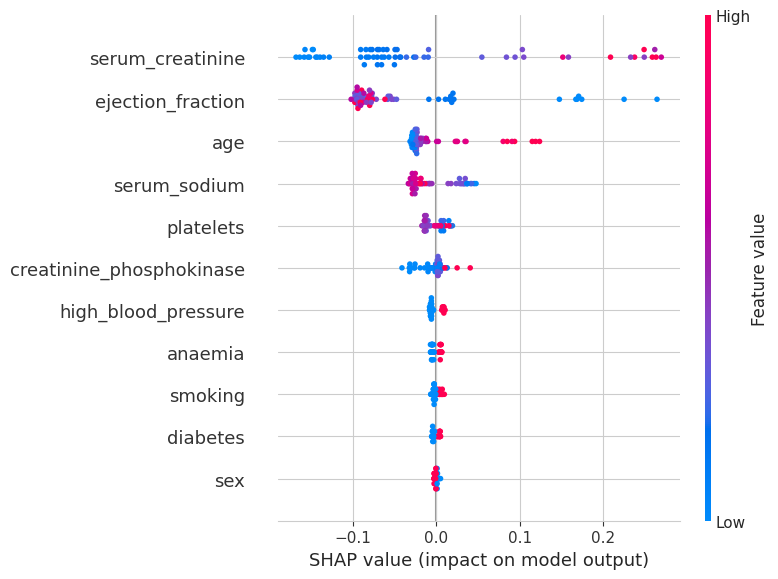

                 feature  mean_abs_shap
        serum_creatinine       0.112437
       ejection_fraction       0.084885
                     age       0.032017
            serum_sodium       0.026574
               platelets       0.010772
creatinine_phosphokinase       0.009830
     high_blood_pressure       0.006890
                 anaemia       0.004974
                 smoking       0.003616
                diabetes       0.003587
                     sex       0.001341


In [18]:

explainer_rf = shap.TreeExplainer(rf_model.named_steps['clf'])
shap_values_rf = explainer_rf.shap_values(X_test_A)
sv_rf_pos = shap_values_rf[:, :, 1] if hasattr(shap_values_rf, 'ndim') and shap_values_rf.ndim == 3 else (
    shap_values_rf[1] if isinstance(shap_values_rf, list) else shap_values_rf)

shap.summary_plot(sv_rf_pos, X_test_A, feature_names=feature_set_A)

mean_abs_shap_rf = pd.DataFrame({'feature': feature_set_A, 'mean_abs_shap': np.abs(sv_rf_pos).mean(axis=0)}) \
                     .sort_values('mean_abs_shap', ascending=False)
print(mean_abs_shap_rf.to_string(index=False))


  0%|          | 0/60 [00:00<?, ?it/s]

  5%|▌         | 3/60 [00:00<00:02, 24.78it/s]

 10%|█         | 6/60 [00:00<00:02, 24.81it/s]

 15%|█▌        | 9/60 [00:00<00:02, 24.96it/s]

 20%|██        | 12/60 [00:00<00:01, 24.96it/s]

...

 85%|████████▌ | 51/60 [00:02<00:00, 24.72it/s]

 90%|█████████ | 54/60 [00:02<00:00, 24.85it/s]

 95%|█████████▌| 57/60 [00:02<00:00, 24.91it/s]

100%|██████████| 60/60 [00:02<00:00, 24.92it/s]

100%|██████████| 60/60 [00:02<00:00, 24.75it/s]

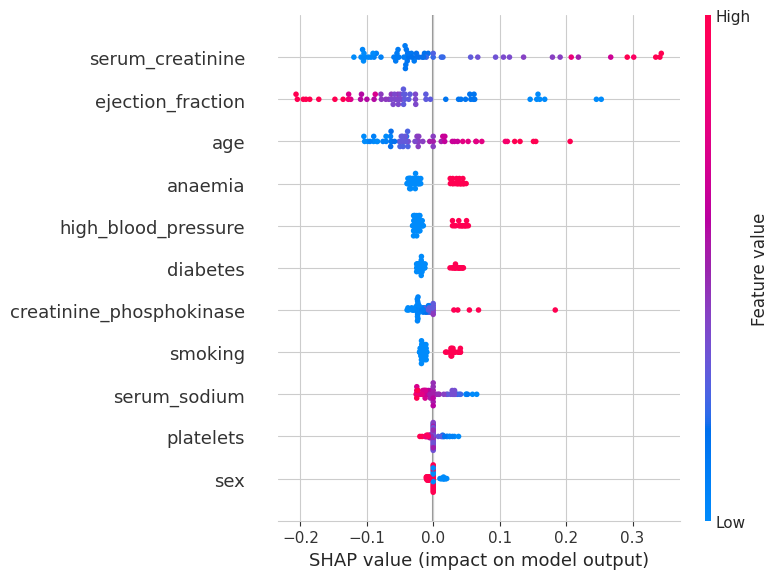

                 feature  mean_abs_shap
        serum_creatinine       0.092023
       ejection_fraction       0.089083
                     age       0.058661
                 anaemia       0.032804
     high_blood_pressure       0.028925
                diabetes       0.024346
creatinine_phosphokinase       0.020996
                 smoking       0.020389
            serum_sodium       0.019577
               platelets       0.007941
                     sex       0.007175


In [19]:

background = shap.sample(X_train_A, 50, random_state=RANDOM_STATE)
explainer_hybrid = shap.KernelExplainer(lambda x: stack.predict_proba(x)[:, 1], background)
shap_values_hybrid = explainer_hybrid.shap_values(X_test_A, nsamples=100)

shap.summary_plot(shap_values_hybrid, X_test_A, feature_names=feature_set_A)

mean_abs_shap_hybrid = pd.DataFrame({'feature': feature_set_A, 'mean_abs_shap': np.abs(shap_values_hybrid).mean(axis=0)}) \
                         .sort_values('mean_abs_shap', ascending=False)
print(mean_abs_shap_hybrid.to_string(index=False))


## 14. Phase 10 — Final Comparison with Bootstrap 95% Confidence Intervals

For the final results table only. Bootstrap resamples the held-out test set (with
replacement, 2000 iterations) to quantify uncertainty around ROC-AUC and F1 for every model,
including the hybrid — this is what lets you say whether differences between models are
actually statistically meaningful given the small test set (n=60).

In [20]:

rng = np.random.RandomState(RANDOM_STATE)
n_boot = 2000
n = len(y_test)
y_test_arr = y_test.values

final_rows = []
for name, r in results.items():
    y_prob, y_pred = r['y_prob'], r['y_pred']
    point_auc = roc_auc_score(y_test_arr, y_prob)
    point_f1 = f1_score(y_test_arr, y_pred)

    boot_aucs, boot_f1s = [], []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        yt = y_test_arr[idx]
        if len(np.unique(yt)) < 2:
            continue
        boot_aucs.append(roc_auc_score(yt, y_prob[idx]))
        boot_f1s.append(f1_score(yt, y_pred[idx]))

    auc_lo, auc_hi = np.percentile(boot_aucs, [2.5, 97.5])
    f1_lo, f1_hi = np.percentile(boot_f1s, [2.5, 97.5])
    final_rows.append({'model': name, 'roc_auc': point_auc, 'roc_auc_ci_lo': auc_lo, 'roc_auc_ci_hi': auc_hi,
                        'f1': point_f1, 'f1_ci_lo': f1_lo, 'f1_ci_hi': f1_hi})

final_df = pd.DataFrame(final_rows).set_index('model')
print(f"{'Model':<22}{'ROC-AUC [95% CI]':<28}{'F1 [95% CI]'}")
for name, row in final_df.iterrows():
    auc_str = f"{row['roc_auc']:.3f} [{row['roc_auc_ci_lo']:.3f}-{row['roc_auc_ci_hi']:.3f}]"
    f1_str  = f"{row['f1']:.3f} [{row['f1_ci_lo']:.3f}-{row['f1_ci_hi']:.3f}]"
    print(f"{name:<22}{auc_str:<28}{f1_str}")

# Note: all confidence intervals overlap substantially at this sample size (n=60 test
# patients) -- no model's discrimination is statistically distinguishable from another's.
# See the accompanying dissertation write-up for full interpretation and discussion.


Model                 ROC-AUC [95% CI]            F1 [95% CI]
Logistic Regression   0.734 [0.588-0.862]         0.513 [0.303-0.683]
LDA                   0.747 [0.600-0.875]         0.452 [0.210-0.649]
Decision Tree         0.764 [0.634-0.892]         0.636 [0.449-0.783]
Random Forest         0.786 [0.662-0.895]         0.579 [0.364-0.750]
XGBoost               0.736 [0.605-0.860]         0.537 [0.333-0.708]
Hybrid (Stacking)     0.760 [0.613-0.878]         0.513 [0.278-0.683]
